In [1]:
import xarray
import xradio
import pathlib
import dougu

import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px


from xradio._utils.zarr.config import ZARR_FORMAT

In [2]:
directory = pathlib.Path.cwd()
asdm_file = directory.parent.joinpath("data/uid___A002_X117bb05_Xa2d1")
#asdm_file = directory.parent.joinpath("notebooks/data/absolute_off/rawdata/uid___A002_Xc1469f_X1c33")
asdm_file

PosixPath('/Users/joshua/Development/ohisama/data/uid___A002_X117bb05_Xa2d1')

In [ ]:
#asdm_dt = xarray.open_datatree(
#    str(asdm_file), 
#    engine="xradio_asdm", 
#    backend_kwargs={
#        "include_processor_types": ["RADIOMETER"]
#    })

In [ ]:
#asdm_dt

In [ ]:
#graph = dougu.graph.Graph.from_dataset(asdm_dt)

In [ ]:
#graph.filter(leaves=[
#    "uid___A002_X117bb05_Xa2d1_00",
#    "uid___A002_X117bb05_Xa2d1_01",
#    "uid___A002_X117bb05_Xa2d1_02",
#    "uid___A002_X117bb05_Xa2d1_03",
#    "uid___A002_X117bb05_Xa2d1_04",
#])

In [3]:
ps_file = asdm_file.name + ".ps.zarr"

In [ ]:
#graph.datatree.to_zarr(store=ps_file, mode="w-", zarr_format=ZARR_FORMAT)

In [4]:
from xradio.measurement_set import open_processing_set

ps_xdt = open_processing_set(ps_file)

In [5]:
ps_file

'uid___A002_X117bb05_Xa2d1.ps.zarr'

In [ ]:
#ps_xdt.xr_ps.summary()

In [6]:
#ps_xdt.xr_ps.query(scan_intents="OBSERVE_TARGET#OFF_SOURCE")
sub_ps = ps_xdt["uid___A002_X117bb05_Xa2d1_02"]

In [13]:
for _sub_ps in ps_xdt.values():
    print(_sub_ps.scan_name.attrs)

{'scan_intents': ["['CALIBRATE_FOCUS']"]}
{'scan_intents': ["['CALIBRATE_POINTING']"]}
{'scan_intents': ["['CALIBRATE_FOCUS']"]}
{'scan_intents': ["['CALIBRATE_POINTING']"]}
{'scan_intents': ["['CALIBRATE_FOCUS']"]}


In [7]:
ps_xdt["uid___A002_X117bb05_Xa2d1_02"]

<xarray.DataTree 'uid___A002_X117bb05_Xa2d1_02'>
Group: /uid___A002_X117bb05_Xa2d1_02
│   Dimensions:                     (time: 3780, baseline_id: 2, frequency: 1,
│                                    polarization: 2)
│   Coordinates:
│     * time                        (time) float64 30kB 1.717e+09 ... 1.717e+09
│       field_name                  (time) <U7 106kB dask.array<chunksize=(3780,), meta=np.ndarray>
│       scan_name                   (time) <U21 318kB dask.array<chunksize=(1890,), meta=np.ndarray>
│     * baseline_id                 (baseline_id) int64 16B 0 1
│       baseline_antenna1_name      (baseline_id) <U4 32B dask.array<chunksize=(2,), meta=np.ndarray>
│       baseline_antenna2_name      (baseline_id) <U4 32B dask.array<chunksize=(2,), meta=np.ndarray>
│     * frequency                   (frequency) float64 8B 9.498e+10
│     * polarization                (polarization) <U2 16B 'XX' 'YY'
│   Data variables:
│       EFFECTIVE_INTEGRATION_TIME  (time, baseline_id) float64 60kB dask.array<chunksize=(3780, 2), meta=np.ndarray>
│       FLAG                        (time, baseline_id, frequency, polarization) bool 15kB dask.array<chunksize=(3780, 2, 1, 2), meta=np.ndarray>
│       TIME_CENTROID               (time, baseline_id) float64 60kB dask.array<chunksize=(3780, 2), meta=np.ndarray>
│       VISIBILITY                  (time, baseline_id, frequency, polarization) float32 60kB dask.array<chunksize=(3780, 2, 1, 2), meta=np.ndarray>
│       WEIGHT                      (time, baseline_id, frequency, polarization) float32 60kB dask.array<chunksize=(3780, 2, 1, 2), meta=np.ndarray>
│   Attributes:
│       schema_version:    4.0.1
│       creator:           {'software_name': 'xradio', 'version': '1.3.0'}
│       creation_date:     2026-11-12T03:47:54.326757+00:00
│       type:              visibility
│       observation_info:  {'observer': ['smwhite'], 'release_date': '', 'project...
│       processor_info:    {'type': 'RADIOMETER', 'sub_type': 'SQUARE_LAW_DETECTOR'}
│       data_groups:       {'base': {'correlated_data': 'VISIBILITY', 'flag': 'FL...
├── Group: /uid___A002_X117bb05_Xa2d1_02/antenna_xds
│       Dimensions:                 (antenna_name: 2, cartesian_pos_label: 3,
│                                    receptor_label: 2)
│       Coordinates:
│         * antenna_name            (antenna_name) <U4 32B 'PM01' 'PM04'
│           mount                   (antenna_name) <U6 48B dask.array<chunksize=(2,), meta=np.ndarray>
│           station_name            (antenna_name) <U4 32B dask.array<chunksize=(2,), meta=np.ndarray>
│           telescope_name          (antenna_name) <U4 32B dask.array<chunksize=(2,), meta=np.ndarray>
│         * cartesian_pos_label     (cartesian_pos_label) <U1 12B 'x' 'y' 'z'
│         * receptor_label          (receptor_label) <U5 40B 'pol_0' 'pol_1'
│           polarization_type       (antenna_name, receptor_label) <U1 16B dask.array<chunksize=(2, 2), meta=np.ndarray>
│       Data variables:
│           ANTENNA_DISH_DIAMETER   (antenna_name) float64 16B dask.array<chunksize=(2,), meta=np.ndarray>
│           ANTENNA_FOCUS_LENGTH    (antenna_name) float64 16B dask.array<chunksize=(2,), meta=np.ndarray>
│           ANTENNA_POSITION        (antenna_name, cartesian_pos_label) float64 48B dask.array<chunksize=(2, 3), meta=np.ndarray>
│           ANTENNA_RECEPTOR_ANGLE  (antenna_name, receptor_label) float64 32B dask.array<chunksize=(2, 2), meta=np.ndarray>
│       Attributes:
│           type:                    antenna
│           relocatable_antennas:    True
│           overall_telescope_name:  ALMA
└── Group: /uid___A002_X117bb05_Xa2d1_02/field_and_source_base_xds
        Dimensions:                           (field_name: 1, sky_dir_label: 2)
        Coordinates:
          * field_name                        (field_name) <U7 28B 'Jupiter'
            source_name                       (field_name) <U7 28B dask.array<chunksize=(1,), meta=np.ndarray>
          * sky_dir_label           

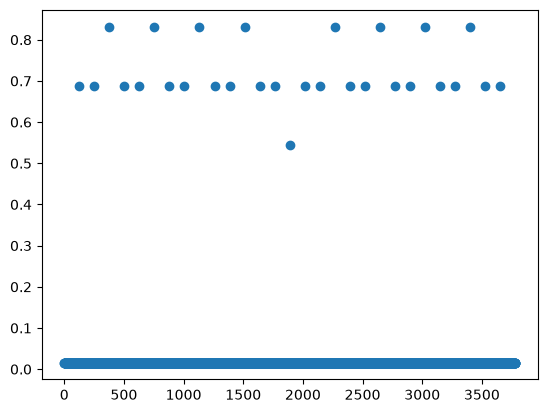

In [23]:
y_length = ps_xdt["uid___A002_X117bb05_Xa2d1_00"].time.data.shape[0]
#x = ps_xdt["uid___A002_X117bb05_Xa2d1_00"].time.data[1:]

y = ps_xdt["uid___A002_X117bb05_Xa2d1_00"].time.data[1:] - ps_xdt["uid___A002_X117bb05_Xa2d1_00"].time.data[:-1]
x = np.linspace(0, y_length-1, y_length-1)

#fig = px.scatter(x=x, y=y)
#fig.show()
plt.scatter(x, y)

In [27]:
def find_gaps(ms):
    gap_index = []
    for index, value in enumerate(ms.time.data):
        
        if index == 0:
            previous = value
            continue
            
        delta = value - previous
        if delta > 0.05:
            gap_index.append(index)

        previous = value

    return gap_index
        

In [68]:
gaps = find_gaps(ps_xdt["uid___A002_X117bb05_Xa2d1_00"])

In [76]:
indicies = np.arange(ps_xdt["uid___A002_X117bb05_Xa2d1_00"].time.data.shape[0])
block_indicies = np.split(indicies, gaps)

In [112]:
reduced_xdt = ps_xdt["uid___A002_X117bb05_Xa2d1_00"].isel(time=block_indicies[0][0:-1])

In [185]:
x = np.array(
    [
        [
            [1, 2],
            [3, 4]
        ],
        [
            [4, 5],
            [6, 4]
        ],
    ]
)

x.shape

X = np.tile(x[..., np.newaxis], [1, 1, 1, 2])

X[..., 1]

array([[[1, 2],
        [3, 4]],

       [[4, 5],
        [6, 4]]])

In [190]:
def compute_solution(chunk):

    time_centroid = chunk.time.mean()
    effective_integration = chunk.EFFECTIVE_INTEGRATION_TIME.data.sum(axis=0)

    valid_data = np.logical_not(chunk.FLAG.data) * chunk.VISIBILITY.data
    
    weight = np.tile(chunk.EFFECTIVE_INTEGRATION_TIME.data[..., np.newaxis, np.newaxis], [1, 1, 1, 2])

    weighted_sum = (valid_data * weight).sum(axis=0)
    weight_total = (np.logical_not(chunk.FLAG.data) * weight).sum(axis=0)

    return (weighted_sum / weight_total).compute()

solutions = []
for integration in block_indicies:
    chunk=ps_xdt["uid___A002_X117bb05_Xa2d1_00"].isel(time=integration[:-1])
    solutions.append(compute_solution(chunk=chunk))
    break

np.array(solutions).shape

(125, 2, 1, 2)
(125, 2, 1, 2)


(1, 2, 1, 2)

In [ ]:
unique_state_ids = np.unique(state_ids)
off_source = filter(lambda x: subscan_intents[x] == "OBSERVE_TARGET#OFF_SOURCE", unique_state_ids)
for sid in off_source:
    # select data by STATE_ID
    selection = np.where(state_ids == sid)[0]

    # reference timestamp
    time_centroid = np.mean(time[selection])

    # total integration time
    effective_exposure = np.sum(exposure[selection])

    # OFF_SOURCE spectrum
    block_data = data[selection]
    block_flag = flag[selection]

    x_valid = np.ma.masked_array(block_data, block_flag)
    weight = exposure[selection]
    wx_sum = np.ma.sum(x_valid * weight.reshape((len(weight), 1, 1)), axis=0)

    w_valid = np.logical_not(block_flag) * weight.reshape((len(weight), 1, 1))
    w_sum = np.ma.sum(np.ma.masked_array(w_valid, block_flag), axis=0)
    solution = wx_sum / w_sum

    # output
    output(solution, time_centroid, effective_exposure)